# **PREDICCIONES**
Es una guía strip de 500nm de ancho por 220 nm de alto de silicio con cladding de óxido de silicio (abajo de la oblea) y aire.
- En esta simulación, el modo fundamental será TE.
- En cuanto a los modos, entiendo que 2 TE y 2 TM con estas dimensiones (no he hecho cálculos).
- El rango de neff estará entre 1.46 (aprox índice del óxido de silicio) y 3.42 (aprox índice del silicio) y crecerá si tenemos aire enxima en vez de óxido encima.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td
#Todo esto no consume créditos porque se ejecuta en local, lo que consume créditos son las llamadas a td.web

lda0 = 1.55 #micrómetros, Tidy3d trabja en micras
freq0 = td.C_0/lda0
w_core = 0.5
h_core = 0.22

**MATERIALES**

In [24]:
print(td.material_library["cSi"].variants.keys())
print(td.material_library["SiO2"].variants.keys())

dict_keys(['Palik_NoLoss', 'Palik_LowLoss', 'Palik_Lossy', 'SalzbergVilla1957', 'Li1993_293K', 'Green2008', 'Green2008_Lossless', 'Si_MultiPhysics'])
dict_keys(['Palik_NoLoss', 'Palik_LowLoss', 'Palik_Lossy', 'Horiba'])


In [25]:
si = td.material_library["cSi"]["Palik_NoLoss"]
siO2 = td.material_library["SiO2"]["Palik_NoLoss"]

In [26]:
print(si.nk_model(freq0)) #esto te devuelve el índice del material y la k en ese orden

(np.float64(3.477203636825235), np.float64(0.0))


In [27]:
print(siO2.nk_model(freq0))

(np.float64(1.4440347085541112), np.float64(0.0))


Escojo el Pakil_NoLoss que está en ambos y no quiero pérdidas porque a la longitud de onda a la que estamos trabajando ambos son transparentes. Como vemos k=0 en ambos, respaldando esto.

**GEOMETRÍA**

In [28]:
#Esto es el box de silicio
guia = td.Structure(geometry=td.Box(center=(0,0,h_core/2),size=(td.inf,w_core,h_core)),medium=si)
guia

Structure(geometry=Box(center=(0.0, 0.0, 0.11), size=(inf, 0.5, 0.22)), name=None, background_permittivity=None, background_medium=None, priority=None,medium=cSi_PalikNoLoss)

In [29]:
#Esto es el box de SiO2
box = td.Structure(geometry=td.Box.from_bounds(rmin=(-td.inf,-td.inf,-100), rmax=(td.inf,td.inf,0)),medium=siO2)
box

Structure(geometry=Box(center=(0.0, 0.0, -50.0), size=(inf, inf, 100.0)), name=None, background_permittivity=None, background_medium=None, priority=None,medium=SiO2_Palik_NoLoss)

El otro medio lo asumo como aire entonces no hay que crear nada más.

**SIMULACIÓN**

In [30]:

print(f'Frecuencia de estudio {freq0*10**(-12)} THz')


Frecuencia de estudio 193.41448903225805 THz


In [31]:
#Primero comprobemos si la frecuencia de los materiales cae dentro de la frecuencia de estudio:
f_min, f_max = si.frequency_range
print(f'{f_min*10**(-12)} THz')
print(f'{f_max*10**(-12)} THz')


49.965409666666666 THz
249.82704833333335 THz


In [32]:
f_min,f_max = siO2.frequency_range
print(f'{f_min*10**(-12)} THz')
print(f'{f_max*10**(-12)} THz')

59.9584916 THz
545.0771963636364 THz


Los dos rangos incluyen 193 THz

In [33]:
sim = td.Simulation(
    center=(0,0,h_core/2),
    size=(1,4,3), #Cuidado con este size, debe ser más grande que la guía, si no por principio de inertidumbre tienes más momento y más energía cinética (k mayor)
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=20,
        wavelength=lda0),
    structures = [box,guia], #Aunque aquí no importe pon guia después porque se superpone lo que va después.
    run_time=1e-12
)

**PLANO DE MODOS Y FIGURA DE SECCIÓN**

In [34]:
from tidy3d.plugins.mode import ModeSolver

In [35]:
plane = td.Box(center=sim.center, size=(0,4,3))
mode_spec = td.ModeSpec(num_modes=4, group_index_step=True)
ms = ModeSolver(simulation=sim, plane=plane, mode_spec=mode_spec, freqs=[freq0])

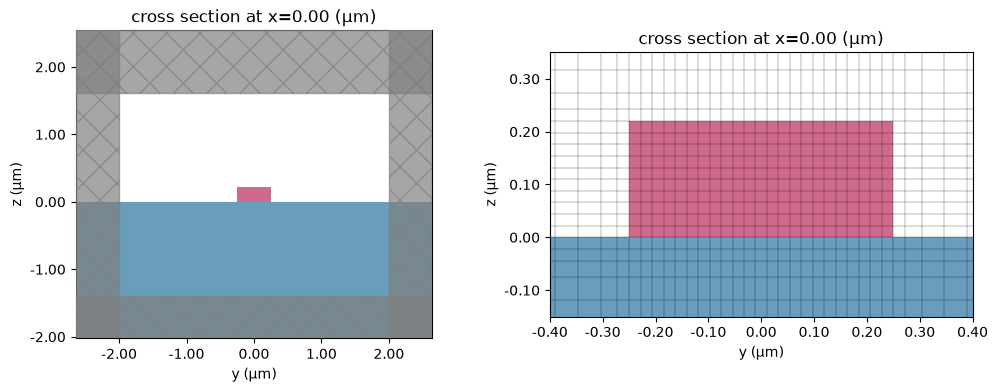

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sim.plot(x=0, ax=ax[0])
sim.plot(x=0, ax=ax[1])
sim.plot_grid(x=0, ax=ax[1])
ax[1].set_xlim(-0.4, 0.4)
ax[1].set_ylim(-0.15, 0.35)
plt.show()

In [37]:
data = ms.solve()
print(data.to_dataframe())

17:00:43 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 1, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 1, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 2, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 2, mode   
                               index 3 does not decay at the plane boundaries.  

                         wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.382829    0.0           0.0   
             1                 1.55  1.594864    0.0           0.0   
             2                 1.55  1.399601    0.0           0.0   
             3                 1.55  1.367790    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.979300        0.728427        0.813077   
             1                   0.079654        0.708310        0.883320   
             2                   0.003272        0.938399        0.969167   
             3                   0.002864        0.971667        0.925126   

                         mode area  group index  dispersion (ps/(nm km))  
f            mode_index                  

In [38]:
cols = ["n eff", "TE (Ey) fraction", "mode area", "group index"]
display(data.to_dataframe()[cols].round(3))

n eff  TE (Ey) fraction  mode area  group index
f            mode_index                                                 
1.934145e+14 0           2.383             0.979      0.189        4.341
             1           1.595             0.080      0.378        3.577
             2           1.400             0.003      2.832        1.601
             3           1.368             0.003      2.899        1.542

**Explicación**

La hipótesis inicial sobre 4 modos confinados era falsa, como vemos solo confinan dos modos confinados, que son aquellos cuyo índice efectivo es mayor al índice de cladding (que es 1.44).

Una forma de ver que no confinan es mirando el área del modo, en los modos 2 y 3 esta área es mucho mayor que en el modo fundamental. 

El modo 0 es TE, dado que su campo en Ey es mayoritario. Por el contrario, el modo 1 es TM (el 92% del campo es vertical, Ez).

Además, el índice de grupo es mayor que neff, es decir neff disminuye cuando aumenta la longitud de onda. A mayor ng más lento va el pulso.

El modo fundamental es el 0 (modo fundamental TE) y el índice efectivo está dentro del rango que habíamos predicho.

Lo que limita el segundo modo es el ancho, un segundo modo TE tiene un nodo a lo ancho, es decir todo dos lóbulos para lo que necesita el doble de ancho (aprox).

In [39]:
#PRUEBA DUPLICANDO EL ANCHO
guia = td.Structure(geometry=td.Box(center=(0,0,h_core/2),size=(td.inf,2*w_core,h_core)),medium=si)
box = td.Structure(geometry=td.Box.from_bounds(rmin=(-td.inf,-td.inf,-100), rmax=(td.inf,td.inf,0)),medium=siO2)
sim_mas_alto = td.Simulation(
    center=(0,0,h_core/2),
    size=(1,4,3), #Cuidado con este size, debe ser más grande que la guía, si no por principio de inertidumbre tienes más momento y más energía cinética (k mayor)
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=20,
        wavelength=lda0),
    structures = [box,guia], #Aunque aquí no importe pon guia después porque se superpone lo que va después.
    run_time=1e-12
)
plane = td.Box(center=sim_mas_alto.center, size=(0,4,3))
mode_spec = td.ModeSpec(num_modes=4, group_index_step=True)
ms_mas_alto = ModeSolver(simulation=sim_mas_alto, plane=plane, mode_spec=mode_spec, freqs=[freq0])
data = ms_mas_alto.solve()
cols = ["n eff", "TE (Ey) fraction", "mode area", "group index"]
display(data.to_dataframe()[cols].round(3))

n eff  TE (Ey) fraction  mode area  group index
f            mode_index                                                 
1.934145e+14 0           2.718             0.998      0.227        3.849
             1           2.373             0.987      0.326        4.381
             2           1.787             0.036      0.481        4.197
             3           1.700             0.859      0.458        5.428

Como hemos ampliado al doble el ancho, el modo 3, que es TE confina. 

Algo interesante es que el modo 2, que es TM, también confina, sigue teniendo el nodo en la vertical.

La polarización dice hacia dónde apunta E; el subíndice, cuántos nodos tiene el campo a lo ancho.

```
 TE₀            TE₁              TM₀           TM₁
┌──────┐      ┌───┬───┐        ┌──────┐      ┌───┬───┐
│  ←→  │      │ → │ ← │        │  ↑   │      │ ↑ │ ↓ │
└──────┘      └───┴───┘        └──────┘      └───┴───┘
 1 lóbulo     2 lóbulos        1 lóbulo      2 lóbulos
 E horiz.     E horiz.         E vertical    E vertical
```

In [40]:
#PRUEBA DUPLICANDO EL ALTO
guia = td.Structure(geometry=td.Box(center=(0,0,2*h_core/2),size=(td.inf,w_core,2*h_core)),medium=si)
box = td.Structure(geometry=td.Box.from_bounds(rmin=(-td.inf,-td.inf,-100), rmax=(td.inf,td.inf,0)),medium=siO2)
sim_mas_ancho = td.Simulation(
    center=(0,0,2*h_core/2),
    size=(1,4,3), #Cuidado con este size, debe ser más grande que la guía, si no por principio de inertidumbre tienes más momento y más energía cinética (k mayor)
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=20,
        wavelength=lda0),
    structures = [box,guia], #Aunque aquí no importe pon guia después porque se superpone lo que va después.
    run_time=1e-12
)
plane = td.Box(center=sim.center, size=(0,4,3))
mode_spec = td.ModeSpec(num_modes=4, group_index_step=True)
ms_mas_ancho = ModeSolver(simulation=sim_mas_ancho, plane=plane, mode_spec=mode_spec, freqs=[freq0])
data = ms_mas_ancho.solve()
cols = ["n eff", "TE (Ey) fraction", "mode area", "group index"]
display(data.to_dataframe()[cols].round(3))

n eff  TE (Ey) fraction  mode area  group index
f            mode_index                                                 
1.934145e+14 0           2.843             0.992      0.226        4.208
             1           2.798             0.011      0.245        4.282
             2           2.110             0.435      0.313        4.622
             3           1.626             0.595      0.446        6.445

Vemos que los modos 2 y 3 también confinan pero ahora tenemos modos híbridos.

**DIBUJO DE LOS MODOS**

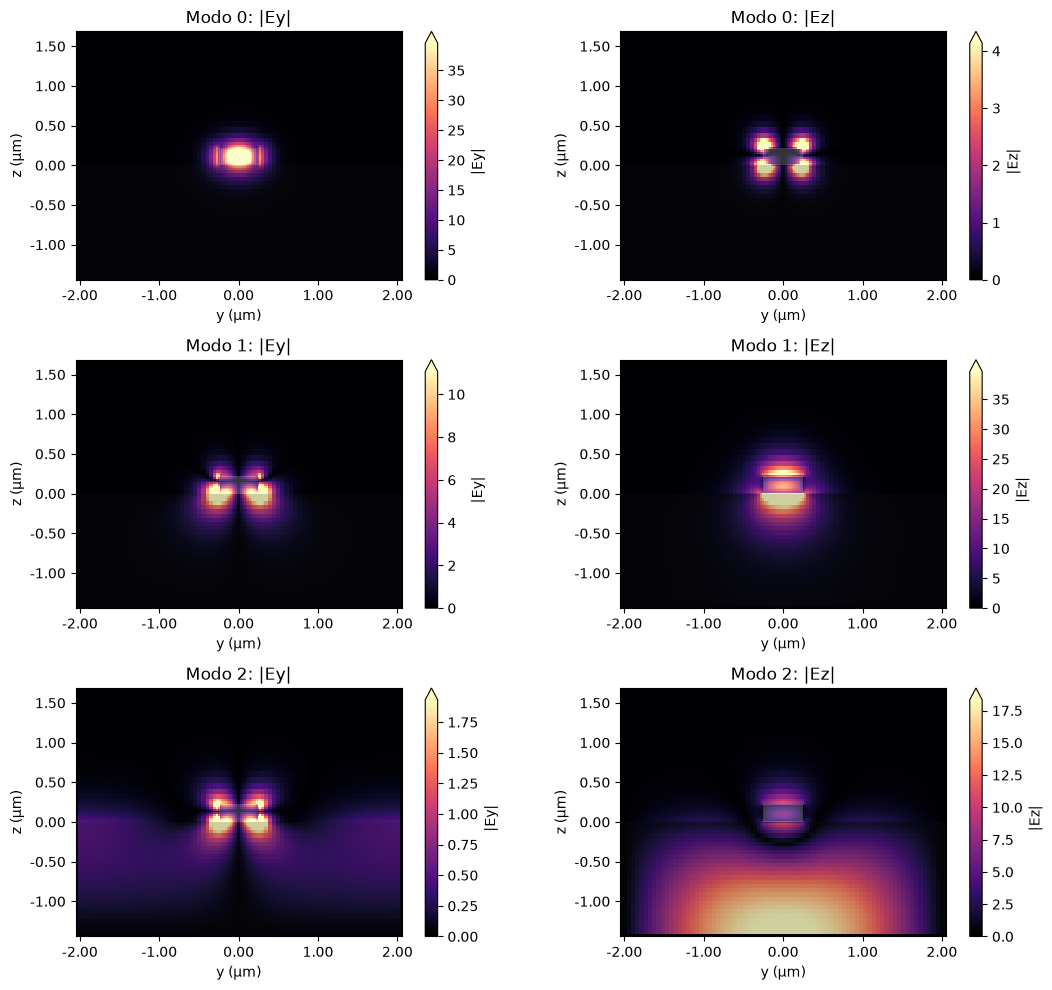

In [45]:
fig, ax = plt.subplots(3,2, figsize=(11,10))
for i in range(3):
    ms.plot_field("Ey", mode_index=i, val="abs", ax=ax[i,0])
    ms.plot_field("Ez", mode_index=i, val="abs", ax=ax[i,1])
    ax[i, 0].set_title(f"Modo {i}: |Ey|")
    ax[i, 1].set_title(f"Modo {i}: |Ez|")
plt.tight_layout()
plt.show()


_Ahora con una escala común_

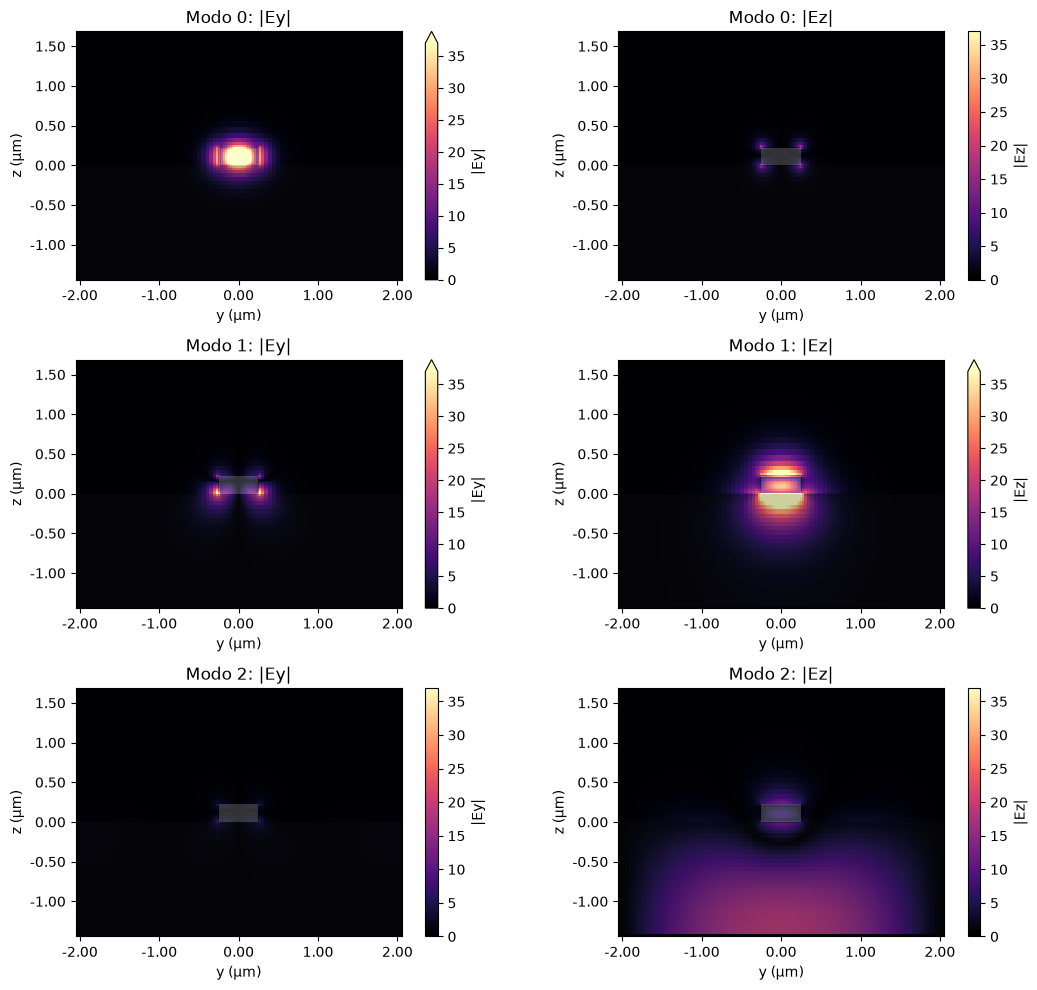

In [46]:
fig, ax = plt.subplots(3,2, figsize=(11,10))
for i in range(3):
    ms.plot_field("Ey", mode_index=i, val="abs", vmin=0, vmax=37, ax=ax[i,0])
    ms.plot_field("Ez", mode_index=i, val="abs", vmin=0, vmax=37, ax=ax[i,1])
    ax[i, 0].set_title(f"Modo {i}: |Ey|")
    ax[i, 1].set_title(f"Modo {i}: |Ez|")
plt.tight_layout()
plt.show()

_Ampliando para ver mejor el núcleo_

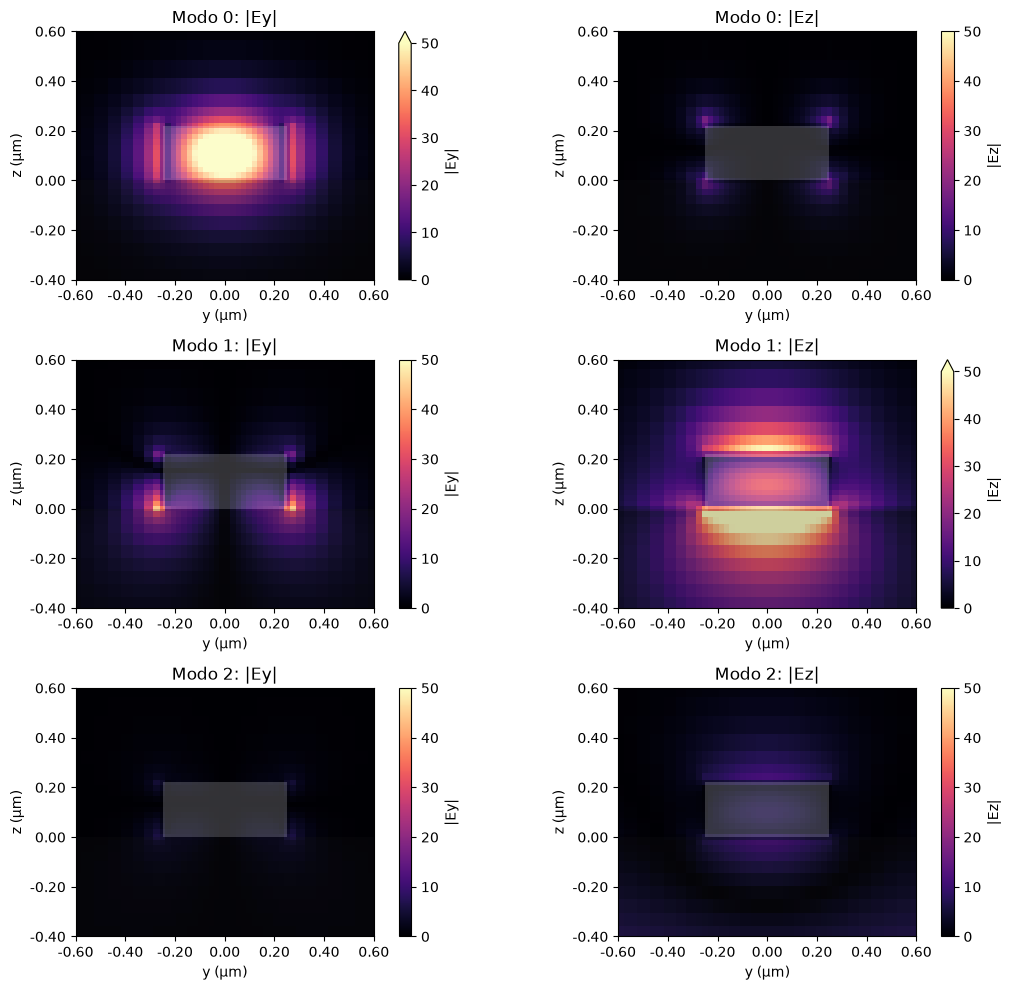

In [65]:
fig, ax = plt.subplots(3,2, figsize=(11,10))
for i in range(3):
    ms.plot_field("Ey", mode_index=i, val="abs", vmin=0, vmax=50, ax=ax[i,0])
    ms.plot_field("Ez", mode_index=i, val="abs", vmin=0, vmax=50, ax=ax[i,1])
    ax[i, 0].set_title(f"Modo {i}: |Ey|")
    ax[i, 1].set_title(f"Modo {i}: |Ez|")
    for a in ax[i]:
        a.set_xlim(-0.6, 0.6)
        a.set_ylim(-0.4, 0.6)
plt.tight_layout()
plt.show()

Esto es la guía sin cambios (sin duplicar sus componentes):

- Modo 0: TE --> Se ven los lóbulos en las paredes laterales y que el campo en Ey es máximo y en Ez mínimo. Observa que los lóbulos son iguales a ambos lados (tenemos mismo cladding, aire).

- Modo 1: TM --> Todo lo contrario al caso anterior en la paredes superior e inferior se ven los lóbulos (discontinuidades del campo) y es predominante en Ez. Aquí los lóbulos sí cambian, en la parte de abajo, donde está el cladding de SiO2 hay más modo, la longitud de decaimiento (γ = k₀·√[n_eff² − n_clad²]) es menor FALTA AÑADIR COSAS AQUÍ ...

- Modo 2: No confina --> No hay campo confinado. Si miras la imagen de arriba, el campo llega a los bordes, concretamente por al de abajo, porque es donde está el SiO2. Tiene que ver con la guía en el sentido de que el índice efectivo del modo es menor que el cladding de abajo lo que hace que se vaya por ahí.

_E frente a H en el modo 0_

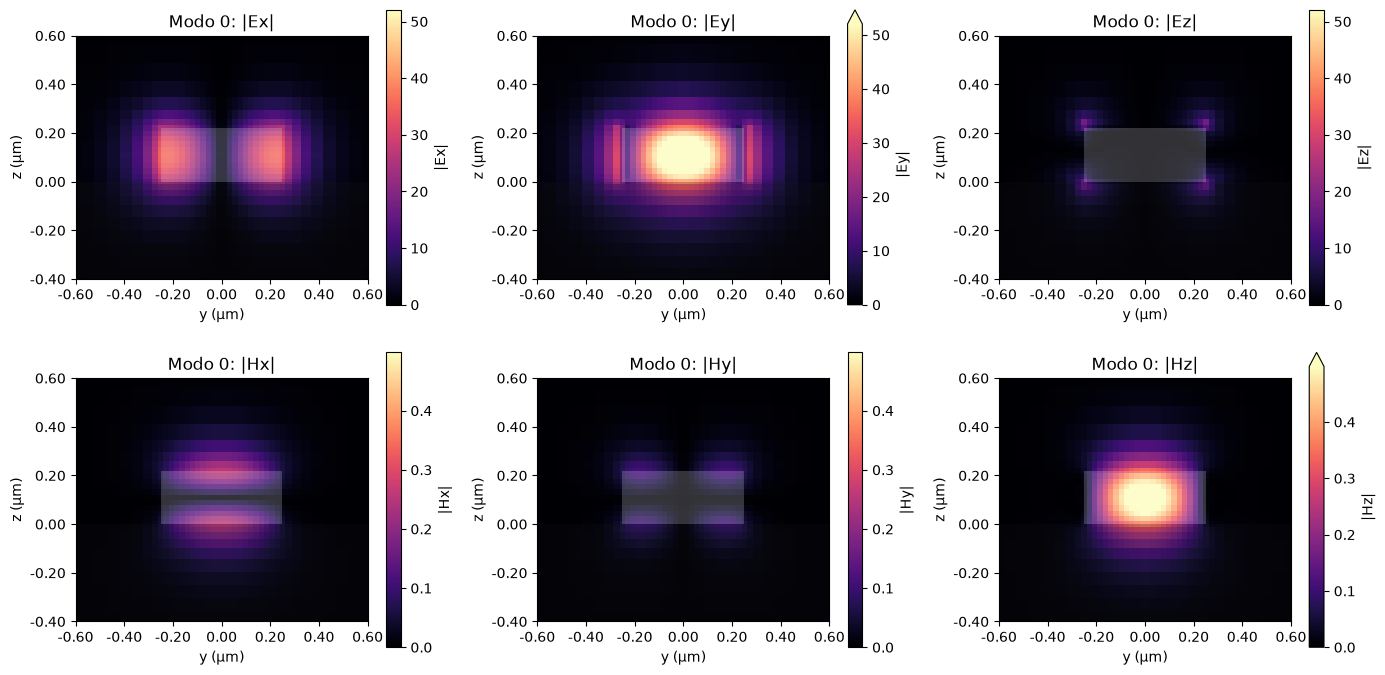

In [63]:
comps = [["Ex", "Ey", "Ez"], ["Hx", "Hy", "Hz"]]
fig, ax = plt.subplots(2, 3, figsize=(14, 7))

for fila in range(2):
    # máximo de esa fila (E o H) para usar una escala común
    vmax = max(float(abs(data.field_components[c].sel(mode_index=0)).max())
               for c in comps[fila])
    for col, c in enumerate(comps[fila]):
        ms.plot_field(c, mode_index=0, val="abs", vmin=0, vmax=vmax, ax=ax[fila, col])
        ax[fila, col].set_title(f"Modo 0: |{c}|")

for a in ax.flat:
    a.set_xlim(-0.6, 0.6)
    a.set_ylim(-0.4, 0.6)

plt.tight_layout()
plt.show()

Falta añadir cosas.

El campo H no tiene discontinuidadades porque los materiales no son magnéticos, así que H es continuo en las interfaces.
E tiene discontinuidades porque la permitividad cambia en las interfaces.
No sé como realacionarlo con el cuasi TE